# DL_PR5 — Sentiment Analysis with RNN, LSTM and GRU
**Student practical notebook | Deep Learning | PR 5**

This notebook follows the supplied project brief. It compares an ANN baseline with SimpleRNN, LSTM, stacked LSTM and GRU on the Kaggle IMDB 50K Movie Reviews CSV.

**Dataset required:** Download `IMDB Dataset.csv` from the Kaggle IMDB 50K Movie Reviews dataset and place it beside this notebook, or update `DATA_PATH` below. The notebook deliberately loads the CSV and performs its own text cleaning, tokenization and padding; it does not use the pre-tokenized Keras IMDB dataset.

**Reproducibility:** random seeds are set. The first run can take a while, especially when training all recurrent models. Use a GPU if available. The notebook uses a subset only if you explicitly change `MAX_ROWS`; by default it uses all rows.

## Task 1 — Dataset loading, cleaning, tokenization and padding
**Objective:** Inspect the raw review data, remove duplicate rows, clean text, analyze review lengths, then create padded integer sequences.  
**Expected output:** Dataset summary, length plots, tokenizer vocabulary size, and train/validation/test tensor shapes.

In [1]:
import os, re, html, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             RocCurveDisplay)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.21.0
NumPy: 2.3.5
Pandas: 2.3.3


In [2]:
# Update this path if your CSV is stored elsewhere.
DATA_PATH = "IMDB Dataset.csv"
MAX_ROWS = None  # Set to e.g. 10000 for a quicker development run; None = all available rows.

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find {DATA_PATH!r}. Download the Kaggle IMDB 50K Movie Reviews CSV "
        "and place it next to this notebook, or change DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Original shape:", df.shape)
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nNull counts:\n", df.isnull().sum())
print("\nRaw sentiment counts:\n", df["sentiment"].value_counts(dropna=False))

required = {"review", "sentiment"}
if not required.issubset(df.columns):
    raise ValueError(f"Expected columns {required}; found {set(df.columns)}")

df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()
df = df[df["sentiment"].isin(["positive", "negative"])].copy()
before = len(df)
df = df.drop_duplicates(subset=["review", "sentiment"]).reset_index(drop=True)
print(f"Removed {before-len(df)} duplicate rows. Clean dataset shape:", df.shape)

if MAX_ROWS is not None:
    # Stratified sample preserves class balance for faster experimentation.
    df = (df.groupby("sentiment", group_keys=False)
            .apply(lambda x: x.sample(min(len(x), max(1, int(MAX_ROWS/2))), random_state=SEED))
            .reset_index(drop=True))
    print("Using sampled shape:", df.shape)

Original shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Column names: ['review', 'sentiment']

Null counts:
 review       0
sentiment    0
dtype: int64

Raw sentiment counts:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Removed 418 duplicate rows. Clean dataset shape: (49582, 2)


### Task 1.2 — Clean the text
HTML tags are removed, text is lowercased, and repeated whitespace is collapsed. We preserve words such as `not`, since negation changes sentiment (for example, “not good”).

In [3]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)       # remove HTML tags
    text = text.lower()
    text = re.sub(r"[^a-z0-9'!?.,\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].map(clean_text)
df["word_count"] = df["clean_review"].str.split().str.len()
display(df[["review", "clean_review", "sentiment", "word_count"]].head())
print(df[["word_count"]].describe(percentiles=[.50, .75, .90, .95, .99]))

,review,clean_review,sentiment,word_count
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive,304
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming tec...,positive,158
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive,167
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...,negative,132
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei's love in the time of money is a...,positive,225


         word_count
count  49582.000000
mean     231.549151
std      171.706469
min        4.000000
50%      173.000000
75%      281.000000
90%      453.000000
95%      590.950000
99%      907.000000
max     2473.000000


### Task 1.3–1.4 — Review length analysis
Compare positive and negative review lengths and use the distribution to select a maximum sequence length. The notebook uses `MAX_LEN = 250` as a practical compromise; truncation keeps the most recent/rightmost end by default in Keras, while padding is added to the left.

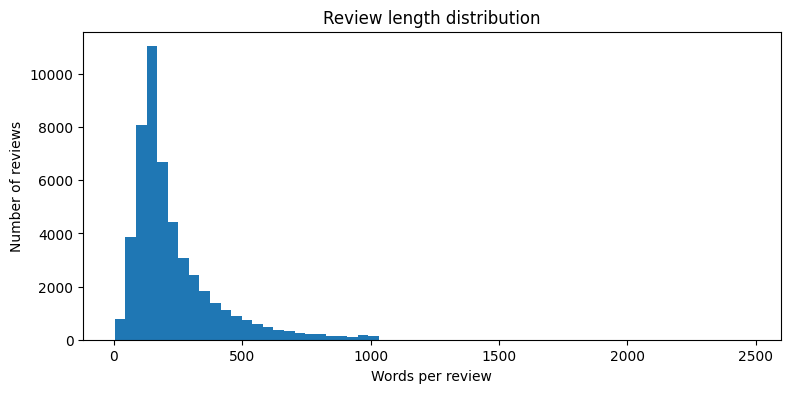

<Figure size 800x400 with 0 Axes>

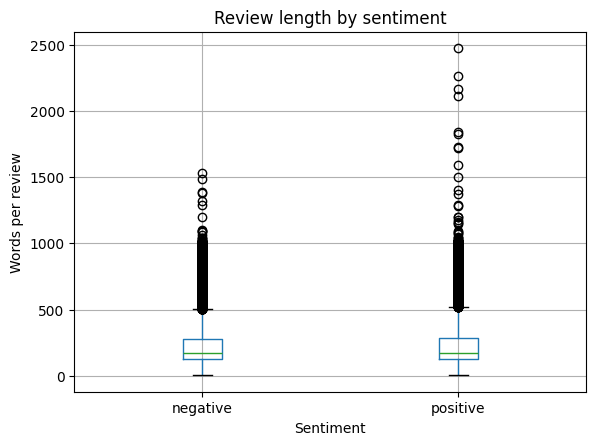

Mean length: 231.55
Median length: 173.0
95th percentile: 590
99th percentile: 907


In [4]:
plt.figure(figsize=(9, 4))
plt.hist(df["word_count"], bins=60)
plt.xlabel("Words per review"); plt.ylabel("Number of reviews")
plt.title("Review length distribution")
plt.show()

plt.figure(figsize=(8, 4))
df.boxplot(column="word_count", by="sentiment")
plt.title("Review length by sentiment"); plt.suptitle("")
plt.xlabel("Sentiment"); plt.ylabel("Words per review")
plt.show()

print("Mean length:", round(df.word_count.mean(), 2))
print("Median length:", round(df.word_count.median(), 2))
print("95th percentile:", int(df.word_count.quantile(.95)))
print("99th percentile:", int(df.word_count.quantile(.99)))

### Task 1.5–1.8 — Tokenize, split, pad
The vocabulary is capped at 10,000 words. Out-of-vocabulary words map to `<OOV>`. The test split is 20% with `random_state=42` and stratification; a validation split is then taken from the training portion.

In [5]:
MAX_WORDS = 10_000
MAX_LEN = 250
EMBED_DIM = 32
BATCH_SIZE = 128
EPOCHS = 8

df["label"] = (df["sentiment"] == "positive").astype("int32")
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_review"].values, df["label"].values,
    test_size=0.20, random_state=SEED, stratify=df["label"].values
)
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_text, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=MAX_WORDS, oov_token="<OOV>", lower=False
)
tokenizer.fit_on_texts(X_train_text)

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return tf.keras.preprocessing.sequence.pad_sequences(
        seqs, maxlen=MAX_LEN, padding="pre", truncating="pre"
    )

X_train = to_padded(X_train_text)
X_val = to_padded(X_val_text)
X_test = to_padded(X_test_text)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
print("Vocabulary in tokenizer:", len(tokenizer.word_index))
print("Vocabulary size used by embedding:", vocab_size)
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Example token IDs:", X_train[0][:30])

Vocabulary in tokenizer: 99725
Vocabulary size used by embedding: 10000
Train: (31732, 250) (31732,)
Validation: (7933, 250) (7933,)
Test: (9917, 250) (9917,)
Example token IDs: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## Task 2 — RNN intuition, ANN vs RNN, and manual forward propagation
**Objective:** Explain the difference between a fixed-vector ANN and a sequence-aware RNN, and verify a single SimpleRNN time step with NumPy.  
**Expected output:** Concept comparison, manual/ Keras numerical check, and parameter-count explanation.

### Task 2.1 — ANN baseline
A simple ANN receives the padded sequence as a fixed vector. It does not explicitly reuse a hidden state from one word position to the next. The Embedding output is flattened before dense layers, so the parameter count grows with `MAX_LEN`.

In [6]:
def build_ann():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN,)),
        tf.keras.layers.Embedding(vocab_size, EMBED_DIM),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ], name="ANN_Baseline")
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

ann = build_ann()
ann.summary()

Model: "ANN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       512,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 832,129 (3.17 MB)

 Trainable params: 832,129 (3.17 MB)

 Non-trainable params: 0 (0.00 B)

### Task 2.2 — Manual SimpleRNN forward step
For one step, the basic recurrence is \(h_t = \tanh(x_t W_x + h_{t-1} W_h + b)\). Keras stores the input kernel, recurrent kernel and bias in the SimpleRNN layer. The example below reproduces the layer computation for one batch/time step.

In [7]:
# A tiny standalone SimpleRNN layer for a transparent numerical check.
tiny = tf.keras.layers.SimpleRNN(3, activation="tanh", use_bias=True, return_sequences=True)
dummy = tf.constant([[[0.2, -0.1], [0.4, 0.3]]], dtype=tf.float32)
_ = tiny(dummy)
Wx, Wh, b = tiny.get_weights()
x_t = dummy.numpy()[0, 0]
h_prev = np.zeros(3, dtype=np.float32)
h_manual = np.tanh(x_t @ Wx + h_prev @ Wh + b)
h_keras = tiny(dummy).numpy()[0, 0]
print("Manual h_1:", h_manual)
print("Keras h_1: ", h_keras)
print("Close:", np.allclose(h_manual, h_keras, atol=1e-6))

Manual h_1: [ 0.1294272  -0.20477244  0.00176457]
Keras h_1:  [ 0.1294272  -0.20477244  0.00176457]
Close: True


### Task 2.3–2.6 — Parameter-count formula and summary
For a SimpleRNN with input dimension \(d\) and \(u\) units, parameters are \(du + u^2 + u\). The recurrent parameter count does not depend on sequence length; the ANN's flattened dense layer does depend on `MAX_LEN`.

In [8]:
d, u = EMBED_DIM, 64
simple_rnn_formula = d*u + u*u + u
print(f"SimpleRNN parameter formula: d*u + u*u + u = {d}*{u} + {u}*{u} + {u} = {simple_rnn_formula}")

comparison_concepts = pd.DataFrame([
    ["ANN baseline", "Fixed vector / flattened positions", "No explicit recurrent state", "Dense weights scale with MAX_LEN"],
    ["RNN", "Processes one time step at a time", "Hidden state carries prior context", "Recurrent weights shared across positions"],
], columns=["Model", "Input handling", "Sequence memory", "Parameter behavior"])
display(comparison_concepts)

SimpleRNN parameter formula: d*u + u*u + u = 32*64 + 64*64 + 64 = 6208


,Model,Input handling,Sequence memory,Parameter behavior
0,ANN baseline,Fixed vector / flattened positions,No explicit recurrent state,Dense weights scale with MAX_LEN
1,RNN,Processes one time step at a time,Hidden state carries prior context,Recurrent weights shared across positions


## Task 3 — Types of RNN and sentiment analysis with SimpleRNN
**Objective:** Identify common RNN mapping patterns and train/evaluate a SimpleRNN sentiment classifier.  
**Expected output:** Mapping examples, training curves, classification metrics and confusion matrix.

### Task 3.1–3.2 — RNN input/output patterns
- **One-to-one:** one input maps to one output, e.g. image classification.
- **One-to-many:** one input produces a sequence, e.g. image captioning.
- **Many-to-one:** a sequence maps to one output, e.g. review sentiment classification.
- **Many-to-many:** a sequence maps to a sequence, e.g. token-level tagging or translation.
For this project, sentiment analysis is many-to-one.

### Shared training/evaluation helpers

In [9]:
results = {}
histories = {}
trained_models = {}

def build_model(kind="SimpleRNN", units=64, stacked=False):
    layers = [tf.keras.layers.Input(shape=(MAX_LEN,)),
              tf.keras.layers.Embedding(vocab_size, EMBED_DIM)]
    if kind == "SimpleRNN":
        layers.append(tf.keras.layers.SimpleRNN(units, return_sequences=False))
    elif kind == "LSTM":
        layers.append(tf.keras.layers.LSTM(units, return_sequences=False))
    elif kind == "Stacked LSTM":
        layers += [tf.keras.layers.LSTM(units, return_sequences=True),
                   tf.keras.layers.LSTM(max(16, units//2), return_sequences=False)]
    elif kind == "GRU":
        layers.append(tf.keras.layers.GRU(units, return_sequences=False))
    else:
        raise ValueError(kind)
    layers += [tf.keras.layers.Dropout(0.3),
               tf.keras.layers.Dense(1, activation="sigmoid")]
    model = tf.keras.Sequential(layers, name=kind.replace(" ", "_"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

def evaluate_model(name, model, history, train_seconds):
    probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    metrics = {
        "Model": name,
        "Parameters": int(model.count_params()),
        "Time per Epoch (s)": round(train_seconds / max(1, len(history.history["loss"])), 3),
        "Epochs Trained": len(history.history["loss"]),
        "Test Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probs),
        "Probabilities": probs,
        "Predictions": preds,
    }
    results[name] = metrics
    trained_models[name] = model
    histories[name] = history
    print(name)
    print(classification_report(y_test, preds, target_names=["negative", "positive"], zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_test, preds))
    return metrics

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
]

In [10]:
# Train ANN baseline
ann = build_ann()
start = time.time()
ann_hist = ann.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
ann_seconds = time.time() - start
evaluate_model("ANN baseline", ann, ann_hist, ann_seconds)

# Train SimpleRNN
simple_rnn = build_model("SimpleRNN", units=64)
start = time.time()
rnn_hist = simple_rnn.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
rnn_seconds = time.time() - start
evaluate_model("SimpleRNN", simple_rnn, rnn_hist, rnn_seconds)

Epoch 1/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7725 - loss: 0.4434 - val_accuracy: 0.8731 - val_loss: 0.2939
Epoch 2/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9293 - loss: 0.1866 - val_accuracy: 0.8671 - val_loss: 0.3292
Epoch 3/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9785 - loss: 0.0739 - val_accuracy: 0.8385 - val_loss: 0.4788
ANN baseline
              precision    recall  f1-score   support

    negative       0.90      0.86      0.88      4940
    positive       0.87      0.90      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917

Confusion matrix:
 [[4268  672]
 [ 495 4482]]
Epoch 1/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - accuracy: 0.6603 - loss: 0.5876 - val_accuracy: 0.8005 - val_loss: 0.4398
Epoch 2/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 13s 52ms/step - accuracy: 0.7627 - loss: 0.4996 - val_accuracy

{'Model': 'SimpleRNN',
 'Parameters': 326273,
 'Time per Epoch (s)': 12.1,
 'Epochs Trained': 5,
 'Test Accuracy': 0.8453161238277705,
 'Precision': 0.8450591300861896,
 'Recall': 0.847096644564999,
 'F1': 0.846076660646197,
 'ROC-AUC': 0.9132009470283955,
 'Probabilities': array([0.01998001, 0.9056299 , 0.7945251 , ..., 0.7040298 , 0.01772085,
        0.94872075], shape=(9917,), dtype=float32),
 'Predictions': array([0, 1, 1, ..., 1, 0, 1], shape=(9917,))}

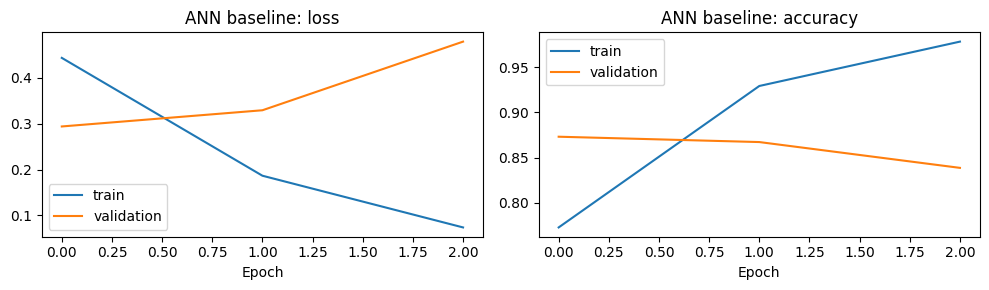

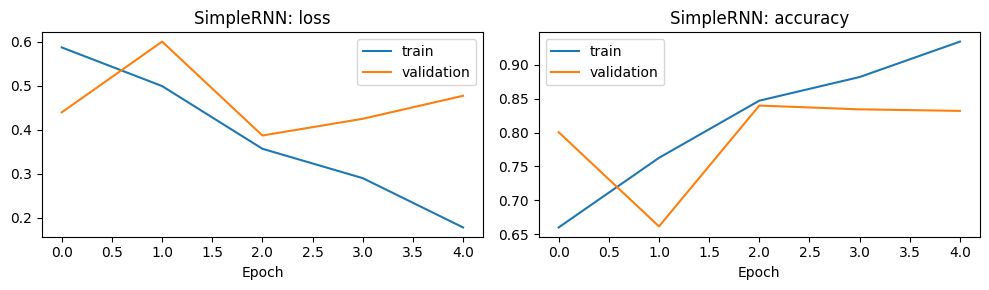

In [11]:
for name, hist in [("ANN baseline", ann_hist), ("SimpleRNN", rnn_hist)]:
    plt.figure(figsize=(10, 3))
    plt.subplot(1, 2, 1)
    plt.plot(hist.history["loss"], label="train")
    plt.plot(hist.history["val_loss"], label="validation")
    plt.title(f"{name}: loss"); plt.xlabel("Epoch"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(hist.history["accuracy"], label="train")
    plt.plot(hist.history["val_accuracy"], label="validation")
    plt.title(f"{name}: accuracy"); plt.xlabel("Epoch"); plt.legend()
    plt.tight_layout(); plt.show()

## Task 4 — Backpropagation Through Time (BPTT) and RNN problems
**Objective:** Explain how gradients are propagated across recurrent time steps and demonstrate gradient norms at different sequence lengths.  
**Expected output:** BPTT explanation, gradient-norm plot and summary of vanishing/exploding gradients.

### Task 4.1–4.2 — Theory
Backpropagation Through Time (BPTT) unfolds a recurrent network across its time steps and applies backpropagation through the unrolled computation graph. Since recurrent weights are shared, each time step contributes to their gradient.

The gradient through many steps contains products of recurrent Jacobians. If repeated factors have magnitude below 1, the gradient can shrink exponentially (**vanishing gradients**) and early words have little influence. If factors have magnitude above 1, the gradient can grow rapidly (**exploding gradients**), causing unstable updates or NaN loss. Gradient clipping, gated architectures (LSTM/GRU), and shorter sequences can help.

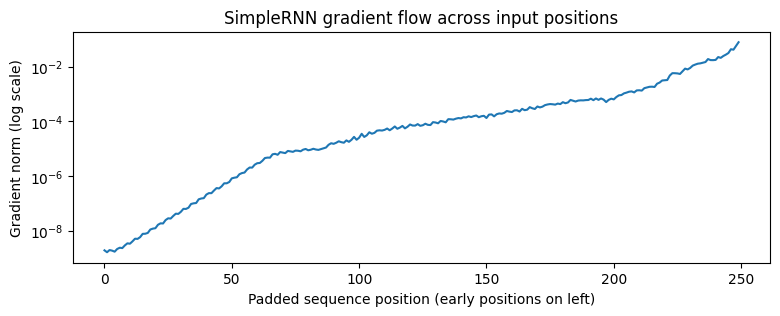

Gradient norm min / median / max: 1.6460323104539043e-09 7.418433233397081e-05 0.07860322296619415


In [12]:
# Gradient-flow probe on the trained SimpleRNN. The gradient is measured from
# the predicted probability for one example back to the embedding output.
def gradient_norm_by_timestep(model, sequence):
    embedding_layer = model.layers[0]
    recurrent_layer = model.layers[1]
    x = tf.convert_to_tensor(sequence[None, :], dtype=tf.int32)
    with tf.GradientTape() as tape:
        emb = embedding_layer(x)
        tape.watch(emb)
        h = recurrent_layer(emb)
        out = model.layers[-1](model.layers[-2](h, training=False), training=False)
        objective = tf.reduce_sum(out)
    grad = tape.gradient(objective, emb).numpy()[0]
    return np.linalg.norm(grad, axis=1)

sample_sequence = X_test[0]
grad_norms = gradient_norm_by_timestep(simple_rnn, sample_sequence)
plt.figure(figsize=(9, 3))
plt.plot(np.arange(MAX_LEN), grad_norms)
plt.yscale("log")
plt.xlabel("Padded sequence position (early positions on left)")
plt.ylabel("Gradient norm (log scale)")
plt.title("SimpleRNN gradient flow across input positions")
plt.show()
print("Gradient norm min / median / max:",
      float(grad_norms.min()), float(np.median(grad_norms)), float(grad_norms.max()))

### Task 4.3–4.6 — Sequence length, exploding gradients and remedies
A longer sequence creates a longer chain of recurrent operations and can make early-token information harder to preserve. Run this optional experiment to compare sequence lengths. A high learning rate may make training unstable; do not assume NaN values are guaranteed because outcomes depend on hardware, initialization and optimizer implementation.

In [13]:
# Lightweight robustness experiment: train fresh SimpleRNNs at different MAX_LEN values.
# This is optional because it repeats training. It reports the sequence length and test accuracy.
def run_length_experiment(lengths=(50, 100, 200, 250), epochs=3):
    rows = []
    for length in lengths:
        xtr = tf.keras.preprocessing.sequence.pad_sequences(
            tokenizer.texts_to_sequences(X_train_text), maxlen=length, padding="pre", truncating="pre")
        xva = tf.keras.preprocessing.sequence.pad_sequences(
            tokenizer.texts_to_sequences(X_val_text), maxlen=length, padding="pre", truncating="pre")
        xte = tf.keras.preprocessing.sequence.pad_sequences(
            tokenizer.texts_to_sequences(X_test_text), maxlen=length, padding="pre", truncating="pre")
        m = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(length,)),
            tf.keras.layers.Embedding(vocab_size, EMBED_DIM),
            tf.keras.layers.SimpleRNN(32),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])
        m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        t0 = time.time()
        h = m.fit(xtr, y_train, validation_data=(xva, y_val), epochs=epochs,
                  batch_size=BATCH_SIZE, verbose=0)
        p = m.predict(xte, batch_size=BATCH_SIZE, verbose=0).ravel()
        rows.append({"Max sequence length": length, "Epochs": len(h.history["loss"]),
                     "Seconds": round(time.time()-t0, 1),
                     "Test accuracy": accuracy_score(y_test, (p >= .5).astype(int))})
    return pd.DataFrame(rows)

# Uncomment to run:
# length_results = run_length_experiment()
# display(length_results)

## Task 5 — LSTM (Long Short-Term Memory)
**Objective:** Explain LSTM gates and cell state, then train and evaluate an LSTM model.  
**Expected output:** LSTM theory, parameter-count formula, learning curves, metrics and gradient-flow comparison.

### Task 5.1–5.3 — LSTM theory and parameter count
An LSTM maintains a **cell state** \(c_t\) and a hidden state \(h_t\). The forget gate controls what old memory to retain, the input gate controls what new information to write, and the output gate controls what part of the cell state becomes the hidden output. The candidate state supplies proposed new content.

For input dimension \(d\) and \(u\) units, a standard Keras LSTM with bias has approximately \(4u(d+u+1)\) parameters: four gate/candidate transformations.

In [14]:
d, u = EMBED_DIM, 64
lstm_formula = 4 * u * (d + u + 1)
print(f"LSTM parameter formula = 4*u*(d+u+1) = 4*{u}*({d}+{u}+1) = {lstm_formula}")

lstm = build_model("LSTM", units=64)
lstm.summary()
start = time.time()
lstm_hist = lstm.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
lstm_seconds = time.time() - start
evaluate_model("LSTM", lstm, lstm_hist, lstm_seconds)

LSTM parameter formula = 4*u*(d+u+1) = 4*64*(32+64+1) = 24832


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 250, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 39s 149ms/step - accuracy: 0.7774 - loss: 0.4624 - val_accuracy: 0.8721 - val_loss: 0.3172
Epoch 2/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 31s 123ms/step - accuracy: 0.8981 - loss: 0.2616 - val_accuracy: 0.8818 - val_loss: 0.2834
Epoch 3/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 120ms/step - accuracy: 0.9162 - loss: 0.2215 - val_accuracy: 0.8771 - val_loss: 0.3053
Epoch 4/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 121ms/step - accuracy: 0.8948 - loss: 0.2600 - val_accuracy: 0.8787 - val_loss: 0.3281
LSTM
              precision    recall  f1-score   support

    negative       0.87      0.90      0.89      4940
    positive       0.90      0.87      0.88      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917

Confusion matrix:
 [[4469  471]
 [ 664 4313]]


{'Model': 'LSTM',
 'Parameters': 344897,
 'Time per Epoch (s)': 32.266,
 'Epochs Trained': 4,
 'Test Accuracy': 0.8855500655440153,
 'Precision': 0.9015468227424749,
 'Recall': 0.8665862969660438,
 'F1': 0.8837209302325582,
 'ROC-AUC': 0.9538385276726382,
 'Probabilities': array([0.01281755, 0.9886619 , 0.9459418 , ..., 0.77651656, 0.01300387,
        0.96790016], shape=(9917,), dtype=float32),
 'Predictions': array([0, 1, 1, ..., 1, 0, 1], shape=(9917,))}

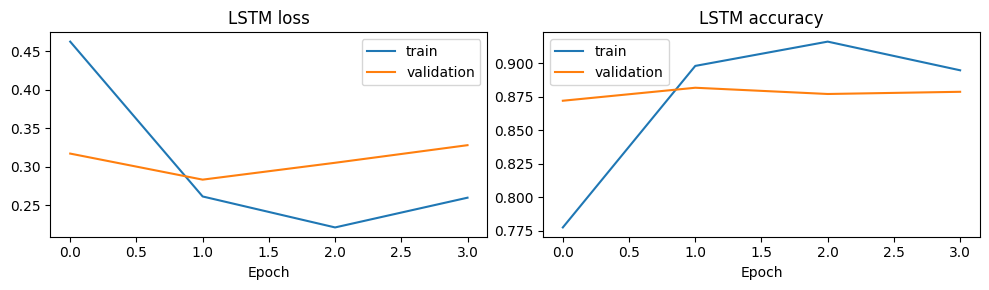

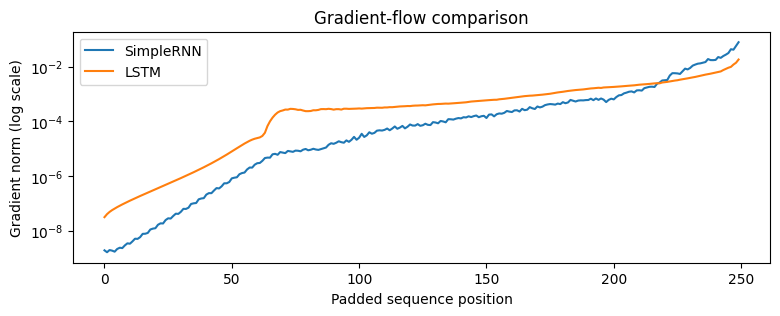

In [15]:
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.plot(lstm_hist.history["loss"], label="train"); plt.plot(lstm_hist.history["val_loss"], label="validation")
plt.title("LSTM loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(lstm_hist.history["accuracy"], label="train"); plt.plot(lstm_hist.history["val_accuracy"], label="validation")
plt.title("LSTM accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout(); plt.show()

lstm_grad_norms = gradient_norm_by_timestep(lstm, X_test[0])
plt.figure(figsize=(9, 3))
plt.plot(grad_norms, label="SimpleRNN")
plt.plot(lstm_grad_norms, label="LSTM")
plt.yscale("log"); plt.xlabel("Padded sequence position"); plt.ylabel("Gradient norm (log scale)")
plt.title("Gradient-flow comparison"); plt.legend(); plt.show()

### Task 5.4–5.7 — Stacked LSTM
Stacking recurrent layers can learn higher-level sequence representations, but it adds parameters and computation and can overfit. The first LSTM must return the full sequence so the next LSTM can process each time step.

In [16]:
stacked_lstm = build_model("Stacked LSTM", units=64)
stacked_lstm.summary()
start = time.time()
stacked_hist = stacked_lstm.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=EPOCHS, batch_size=BATCH_SIZE,
                                callbacks=callbacks, verbose=1)
stacked_seconds = time.time() - start
evaluate_model("Stacked LSTM", stacked_lstm, stacked_hist, stacked_seconds)

Model: "Stacked_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 250, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 250, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 60s 236ms/step - accuracy: 0.7848 - loss: 0.4364 - val_accuracy: 0.8819 - val_loss: 0.2887
Epoch 2/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 52s 210ms/step - accuracy: 0.8986 - loss: 0.2574 - val_accuracy: 0.8615 - val_loss: 0.3272
Epoch 3/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 50s 203ms/step - accuracy: 0.9230 - loss: 0.2037 - val_accuracy: 0.8763 - val_loss: 0.3108
Stacked LSTM
              precision    recall  f1-score   support

    negative       0.89      0.88      0.88      4940
    positive       0.88      0.89      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917

Confusion matrix:
 [[4331  609]
 [ 548 4429]]


{'Model': 'Stacked LSTM',
 'Parameters': 357281,
 'Time per Epoch (s)': 54.319,
 'Epochs Trained': 3,
 'Test Accuracy': 0.8833316527175558,
 'Precision': 0.8791186978959905,
 'Recall': 0.8898935101466747,
 'F1': 0.8844732900649026,
 'ROC-AUC': 0.951730775331708,
 'Probabilities': array([0.02286307, 0.9762113 , 0.923277  , ..., 0.16361926, 0.02121263,
        0.90661836], shape=(9917,), dtype=float32),
 'Predictions': array([0, 1, 1, ..., 0, 0, 1], shape=(9917,))}

## Task 6 — GRU (Gated Recurrent Unit)
**Objective:** Explain the GRU update/reset gates and train/evaluate a GRU with the same data split.  
**Expected output:** GRU theory, parameter formula, metrics, gradient comparison and hidden-unit sensitivity experiment.

### Task 6.1–6.3 — GRU theory and parameter count
A GRU uses an **update gate** to balance old hidden state and new candidate state, and a **reset gate** to control how much previous state contributes to the candidate. It merges some of the LSTM's gating functions and does not maintain a separate cell state.

For a standard Keras GRU with reset-after bias, a common parameter-count formula is \(3u(d+u+2)\): three transformations for update, reset and candidate, with two bias vectors. Exact counts can vary with implementation options.

In [17]:
d, u = EMBED_DIM, 64
gru_formula = 3 * u * (d + u + 2)
print(f"Approx. GRU parameter formula = 3*u*(d+u+2) = 3*{u}*({d}+{u}+2) = {gru_formula}")

gru = build_model("GRU", units=64)
gru.summary()
start = time.time()
gru_hist = gru.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
gru_seconds = time.time() - start
evaluate_model("GRU", gru, gru_hist, gru_seconds)

Approx. GRU parameter formula = 3*u*(d+u+2) = 3*64*(32+64+2) = 18816


Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 250, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 42s 163ms/step - accuracy: 0.7665 - loss: 0.4624 - val_accuracy: 0.8601 - val_loss: 0.3310
Epoch 2/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 44s 177ms/step - accuracy: 0.8844 - loss: 0.2864 - val_accuracy: 0.8544 - val_loss: 0.3501
Epoch 3/8
248/248 ━━━━━━━━━━━━━━━━━━━━ 36s 145ms/step - accuracy: 0.9034 - loss: 0.2479 - val_accuracy: 0.8655 - val_loss: 0.3787
GRU
              precision    recall  f1-score   support

    negative       0.87      0.85      0.86      4940
    positive       0.86      0.87      0.87      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917

Confusion matrix:
 [[4218  722]
 [ 631 4346]]


{'Model': 'GRU',
 'Parameters': 338881,
 'Time per Epoch (s)': 40.662,
 'Epochs Trained': 3,
 'Test Accuracy': 0.8635676111727337,
 'Precision': 0.8575374901341752,
 'Recall': 0.8732167972674302,
 'F1': 0.8653061224489796,
 'ROC-AUC': 0.9379290078490612,
 'Probabilities': array([0.02824699, 0.96385485, 0.90556496, ..., 0.42528665, 0.03894278,
        0.7130936 ], shape=(9917,), dtype=float32),
 'Predictions': array([0, 1, 1, ..., 0, 0, 1], shape=(9917,))}

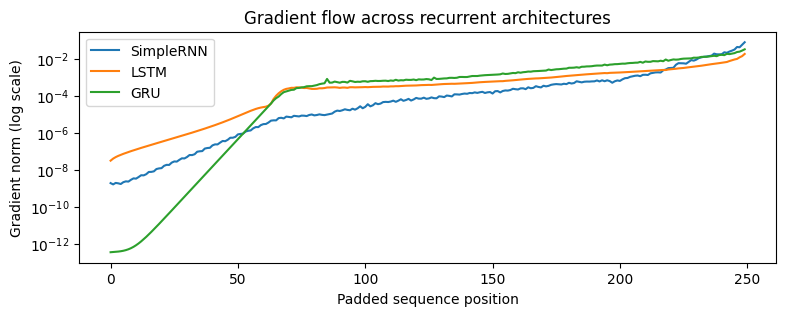

In [18]:
gru_grad_norms = gradient_norm_by_timestep(gru, X_test[0])
plt.figure(figsize=(9, 3))
plt.plot(grad_norms, label="SimpleRNN")
plt.plot(lstm_grad_norms, label="LSTM")
plt.plot(gru_grad_norms, label="GRU")
plt.yscale("log"); plt.xlabel("Padded sequence position"); plt.ylabel("Gradient norm (log scale)")
plt.title("Gradient flow across recurrent architectures"); plt.legend(); plt.show()

### Task 6.4–6.6 — Hidden-unit sensitivity
The following optional experiment trains GRUs with different unit counts. More units generally increase representational capacity and parameter count, but also increase training time and overfitting risk. Compare test metrics rather than assuming that the largest model is best.

In [19]:
def run_gru_unit_experiment(unit_values=(32, 64, 128), epochs=3):
    rows = []
    for units in unit_values:
        m = build_model("GRU", units=units)
        t0 = time.time()
        h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                  batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)
        p = m.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
        pred = (p >= .5).astype(int)
        rows.append({"GRU units": units, "Parameters": m.count_params(),
                     "Time/epoch (s)": round((time.time()-t0)/max(1, len(h.history["loss"])), 3),
                     "Accuracy": accuracy_score(y_test, pred),
                     "F1": f1_score(y_test, pred, zero_division=0),
                     "ROC-AUC": roc_auc_score(y_test, p)})
    return pd.DataFrame(rows)

# Uncomment to run:
# gru_unit_results = run_gru_unit_experiment()
# display(gru_unit_results)

## Task 7 — Final comparison, inference and recommendation
**Objective:** Compare all trained models, plot ROC curves, examine performance by review length, inspect errors, and provide a reusable inference function.  
**Expected output:** Metrics CSV, ROC curve, robustness table, misclassified examples, inference examples and recommendation.

In [20]:
# Compact results table; probability/prediction arrays are excluded from the displayed table.
metric_cols = ["Model", "Parameters", "Time per Epoch (s)", "Epochs Trained",
               "Test Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
results_df = pd.DataFrame([{k: v for k, v in item.items() if k in metric_cols}
                           for item in results.values()])
results_df = results_df.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df.style.highlight_max(
    subset=["Test Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], color="#d7f0d1"))
results_df.to_csv("pr5_model_comparison.csv", index=False)
print("Saved pr5_model_comparison.csv")

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,LSTM,344897,32.266000,4,0.885550,0.901547,0.866586,0.883721,0.953839
1,Stacked LSTM,357281,54.319000,3,0.883332,0.879119,0.889894,0.884473,0.951731
2,ANN baseline,832129,2.954000,3,0.882323,0.869616,0.900542,0.884809,0.951114
3,GRU,338881,40.662000,3,0.863568,0.857537,0.873217,0.865306,0.937929
4,SimpleRNN,326273,12.100000,5,0.845316,0.845059,0.847097,0.846077,0.913201


Saved pr5_model_comparison.csv


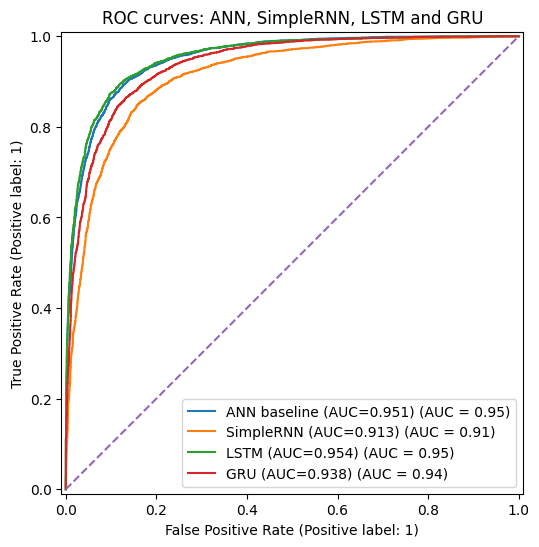

In [21]:
plt.figure(figsize=(7, 6))
for name in ["ANN baseline", "SimpleRNN", "LSTM", "GRU"]:
    if name not in results:
        continue
    probs = results[name]["Probabilities"]
    RocCurveDisplay.from_predictions(y_test, probs, name=f"{name} (AUC={results[name]['ROC-AUC']:.3f})", ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC curves: ANN, SimpleRNN, LSTM and GRU")
plt.show()

### Task 7.3 — Sequence-length robustness
Review length can affect classification because truncation may remove useful context and long sequences are harder to process. Run the optional sequence-length experiment from Task 4.5 if you need empirical measurements. Do not claim a trend until you have run it and examined the table.

In [22]:
# Evaluate the best model's errors. Best is selected by test ROC-AUC for this practical report.
best_name = max(results, key=lambda n: results[n]["ROC-AUC"])
best_model = trained_models[best_name]
best_probs = results[best_name]["Probabilities"]
best_preds = results[best_name]["Predictions"]
print("Best model by test ROC-AUC:", best_name)

error_df = pd.DataFrame({
    "true_label": y_test,
    "predicted_label": best_preds,
    "probability_positive": best_probs,
    "clean_review": X_test_text,
    "word_count": [len(x.split()) for x in X_test_text]
})
errors = error_df[error_df.true_label != error_df.predicted_label]
false_positives = errors[(errors.true_label == 0) & (errors.predicted_label == 1)].head(4)
false_negatives = errors[(errors.true_label == 1) & (errors.predicted_label == 0)].head(4)
print("False positives (negative review predicted positive):")
display(false_positives[["true_label", "predicted_label", "probability_positive", "clean_review"]])
print("False negatives (positive review predicted negative):")
display(false_negatives[["true_label", "predicted_label", "probability_positive", "clean_review"]])

Best model by test ROC-AUC: LSTM
False positives (negative review predicted positive):


,true_label,predicted_label,probability_positive,clean_review
17,0,1,0.529102,i see this movie as a poor tribute to the old ...
24,0,1,0.575461,despite being a huge fan of fred astaire and g...
79,0,1,0.565509,"using tons of stock footage, not only from tra..."
95,0,1,0.922435,"i am a huge, huge fan of john cusack, samuel l..."


False negatives (positive review predicted negative):


,true_label,predicted_label,probability_positive,clean_review
12,1,0,0.485234,the movie takes place during the year 1940 and...
15,1,0,0.165742,"this isn't exactly a great film, but i admire ..."
35,1,0,0.116715,"well, well....roeg touched a bit of a nerve th..."
45,1,0,0.089104,i'm not here to tell you armored is kubrickian...


### Task 7.4 — Error analysis prompts
When reviewing the printed errors, look for:
- **Negation:** “not good” may contain the positive word “good” but express a negative opinion.
- **Sarcasm:** literal positive words can be used sarcastically.
- **Very short reviews:** fewer contextual clues are available.
- **Long reviews:** the selected maximum length can truncate important content.
- **Mixed sentiment:** a review may praise one aspect and criticize another.

Write observations based on the examples printed in your run; do not invent examples as if they were model errors.

In [23]:
def predict_sentiment(texts, model=best_model, threshold=0.5):
    """Predict positive/negative sentiment for one string or a list of strings."""
    if isinstance(texts, str):
        texts = [texts]
    cleaned = [clean_text(t) for t in texts]
    padded = to_padded(cleaned)
    probabilities = model.predict(padded, verbose=0).ravel()
    output = []
    for text, prob in zip(texts, probabilities):
        output.append({
            "text": text,
            "predicted_sentiment": "positive" if prob >= threshold else "negative",
            "positive_probability": float(prob)
        })
    return output

custom_reviews = [
    "This movie was wonderful and the acting was excellent.",
    "I did not enjoy this movie; the story was boring.",
    "Not bad at all, surprisingly entertaining.",
    "The film was so amazing... if you enjoy wasting two hours.",
    "Good.",
    "I expected a great film but it was not good."
]
display(pd.DataFrame(predict_sentiment(custom_reviews)))

,text,predicted_sentiment,positive_probability
0,This movie was wonderful and the acting was ex...,positive,0.986650
1,I did not enjoy this movie; the story was boring.,positive,0.512599
2,"Not bad at all, surprisingly entertaining.",positive,0.976714
3,The film was so amazing... if you enjoy wastin...,positive,0.869295
4,Good.,positive,0.998111
5,I expected a great film but it was not good.,positive,0.941160


### Task 7.5 — Recommendation
Use the measured comparison table to make the final selection. In general, SimpleRNN is a useful baseline but can struggle with long-range dependencies; LSTM often preserves longer context through its cell state; GRU is a simpler gated alternative that can offer a favorable accuracy/compute trade-off; stacked LSTM may help when extra capacity is justified but costs more time and parameters.

**Production recommendation template:** Select the model with the best validation/test trade-off, not merely the highest training accuracy. Consider ROC-AUC and F1 alongside accuracy, latency, parameter count, model size, and behavior on long/negated/sarcastic reviews. Report your actual measured winner from `results_df` and explain the trade-off in your own words.

## Final checklist / viva preparation
- [ ] Dataset is the raw Kaggle CSV; cleaning, tokenization and padding are done in this notebook.
- [ ] Duplicate removal happens before the train/test split.
- [ ] Test split uses `test_size=0.20`, `random_state=42`, and stratification.
- [ ] ANN, SimpleRNN, LSTM, stacked LSTM and GRU are trained and evaluated.
- [ ] Training curves, confusion matrices, classification reports and ROC curves are included.
- [ ] Parameter counts, gradient flow and sequence-length/unit experiments are discussed.
- [ ] `pr5_model_comparison.csv` is saved after successful model training.
- [ ] Restart kernel and Run All; verify there are no errors.
- [ ] Record a 5–10 minute video with your face and notebook screen visible, explain the concepts aloud, upload it, and add the link to README.
- [ ] Create a public GitHub repository with notebook, README, requirements file and video link. Do not upload the dataset if its license/size makes that inappropriate.